# ❤️ Heart Disease Risk Prediction — Clinical Triage Decision-Support
**Course:** AIDS Department — Problem-Based Learning (PBL) &nbsp;|&nbsp; **Student:** Rohit Dnyaneshwar Mahale &nbsp;|&nbsp; **PRN:** 2125UDSM2043 &nbsp;|&nbsp; **Class:** TY AIDS-B (Third Year) &nbsp;|&nbsp; **Dataset:** Heart Failure Prediction (Kaggle, fedesoriano) — 918 patients, 11 clinical features

**Notebook map (aligned to the PBL rubric)**

| § | Section | Rubric criterion |
|---|---|---|
| 1 | Problem definition & business understanding | 1 |
| 2 | Dataset & data understanding | 2 |
| 3 | Data preprocessing & cleaning | 3 |
| 4 | Exploratory data analysis | 4 |
| 5 | Feature engineering / selection / leakage control | 5 |
| 6 | Model selection & implementation | 6 |
| 7 | Model evaluation & validation | 7 |
| 8 | Business insights & recommendations | 8 |
| 9 | Deployment, limitations, contributions | 9 |

## 1. Problem Definition & Business Understanding

### 1.1 Problem statement
Cardiovascular disease (CVD) is the world's leading cause of death (WHO: ~17.9 million deaths a year). In primary-care and screening-camp settings, doctors see many patients but have **limited cardiology appointments, ECG/stress-test capacity and time**. A patient with early heart disease who is *not* flagged may leave without follow-up; a healthy patient who *is* flagged consumes a scarce specialist slot.

> **Problem:** Given routine, low-cost clinical measurements taken at a screening visit (age, sex, chest-pain type, resting BP, cholesterol, fasting blood sugar, resting ECG, exercise test results), **predict whether a patient has heart disease** so that clinicians can **prioritise high-risk patients for cardiology referral**.

### 1.2 Objectives
1. Build a **leakage-free, reproducible ML pipeline** that predicts `HeartDisease` (binary).
2. Achieve **high recall (sensitivity ≥ 90 %)** — missing a sick patient is the costly error — while keeping precision reasonable.
3. Identify **which clinical factors drive risk** and convert them into screening guidance.
4. Provide a **risk-tier output (Low / Moderate / High)** and a **deployable web app** for demonstration.

### 1.3 Stakeholders
| Stakeholder | Interest |
|---|---|
| General practitioners / screening-camp doctors | Fast, explainable second opinion at point of care |
| Cardiology department / hospital admin | Better use of limited specialist, ECG and stress-test capacity |
| Patients | Earlier detection and treatment |
| Health insurers / public-health programmes | Lower cost of late-stage treatment |

### 1.4 Business relevance & KPIs
| KPI | Target | Why |
|---|---|---|
| **Recall (sensitivity)** | ≥ 0.90 | Missed disease (false negative) is the most dangerous/expensive error |
| **Precision** | ≥ 0.80 | Keeps unnecessary referrals manageable |
| **F1-score** | ≥ 0.85 | Balance of the two |
| **ROC-AUC** | ≥ 0.90 | Threshold-independent ranking quality |
| **Expected cost per 100 patients** | Minimise (FN assumed 10× costlier than FP) | Converts ML error into business terms |

> ⚠️ **Scope note:** this is a *decision-support / triage* prototype trained on a small public dataset. It is **not** a diagnostic device and must not replace clinical judgement.

## 0. Setup

In [1]:
import os, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)

from heart_utils import (FeatureEngineer, IQRClipper, build_preprocessor, make_model_pipeline,
                         RAW_FEATURES, TARGET, CATEGORICAL, CONTINUOUS, BINARY)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
os.makedirs("figures", exist_ok=True); os.makedirs("model", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Dataset & Data Understanding
**Source:** *Heart Failure Prediction Dataset* (Kaggle, `fedesoriano`, 2021) — a combination of 5 independent heart-disease datasets (Cleveland, Hungarian, Switzerland, Long Beach VA, Stalog) over 11 common features; 918 unique patients after removing duplicates. License: Open Database License (ODbL).

> The relative path below works when `heart.csv` sits next to this notebook (it is included in the project folder). A public mirror is used as a fallback.

In [2]:
DATA_PATH = "heart.csv"
MIRROR = "https://raw.githubusercontent.com/Jayraj-Dhaigude/Heart-Disease-Prediction/main/heart.csv"
df = pd.read_csv(DATA_PATH if os.path.exists(DATA_PATH) else MIRROR)
print("Shape:", df.shape)
df.head()

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 2.1 Data dictionary

In [3]:
data_dictionary = pd.DataFrame([
 ("Age","Numeric (int)","Age of patient","years (28–77)"),
 ("Sex","Categorical","Sex of patient","M / F"),
 ("ChestPainType","Categorical","Type of chest pain","TA typical angina · ATA atypical angina · NAP non-anginal pain · ASY asymptomatic"),
 ("RestingBP","Numeric (int)","Resting systolic blood pressure","mm Hg"),
 ("Cholesterol","Numeric (int)","Serum cholesterol","mg/dl (0 = not recorded)"),
 ("FastingBS","Binary","Fasting blood sugar > 120 mg/dl","1 = yes, 0 = no"),
 ("RestingECG","Categorical","Resting ECG result","Normal · ST (ST-T wave abnormality) · LVH (left ventricular hypertrophy)"),
 ("MaxHR","Numeric (int)","Maximum heart rate achieved in exercise test","bpm (60–202)"),
 ("ExerciseAngina","Binary","Exercise-induced angina","Y / N"),
 ("Oldpeak","Numeric (float)","ST depression induced by exercise relative to rest","mm"),
 ("ST_Slope","Categorical","Slope of the peak-exercise ST segment","Up · Flat · Down"),
 ("HeartDisease","Binary (TARGET)","Heart disease present","1 = disease, 0 = normal"),
], columns=["Feature","Type","Description","Values / Units"])
data_dictionary

,Feature,Type,Description,Values / Units
0,Age,Numeric (int),Age of patient,years (28–77)
1,Sex,Categorical,Sex of patient,M / F
2,ChestPainType,Categorical,Type of chest pain,TA typical angina · ATA atypical angina · NAP ...
3,RestingBP,Numeric (int),Resting systolic blood pressure,mm Hg
4,Cholesterol,Numeric (int),Serum cholesterol,mg/dl (0 = not recorded)
5,FastingBS,Binary,Fasting blood sugar > 120 mg/dl,"1 = yes, 0 = no"
6,RestingECG,Categorical,Resting ECG result,Normal · ST (ST-T wave abnormality) · LVH (lef...
7,MaxHR,Numeric (int),Maximum heart rate achieved in exercise test,bpm (60–202)
8,ExerciseAngina,Binary,Exercise-induced angina,Y / N
9,Oldpeak,Numeric (float),ST depression induced by exercise relative to ...,mm


### 2.2 Structure, types and summary statistics

In [4]:
df.info()
display(df.describe().T.round(2))
display(df.describe(include="object").T)

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.55,0.50,0.0,0.00,1.0,1.0,1.0


,count,unique,top,freq
Sex,918,2,M,725
ChestPainType,918,4,ASY,496
RestingECG,918,3,Normal,552
ExerciseAngina,918,2,N,547
ST_Slope,918,3,Flat,460


### 2.3 Data-quality audit

In [5]:
quality = pd.DataFrame({
 "Check": ["Rows × columns","Missing values (NaN)","Duplicate rows","Cholesterol == 0 (impossible → not recorded)",
           "RestingBP == 0 (impossible)","Oldpeak < 0","Class balance (HeartDisease = 1)"],
 "Result": [f"{df.shape[0]} × {df.shape[1]}", int(df.isna().sum().sum()), int(df.duplicated().sum()),
            f"{(df.Cholesterol==0).sum()} rows ({(df.Cholesterol==0).mean():.1%})", int((df.RestingBP==0).sum()),
            f"{(df.Oldpeak<0).sum()} rows (valid: ST *elevation*)", f"{df[TARGET].mean():.1%}"]})
display(quality)

chol0 = df.assign(Cholesterol_is_0=(df.Cholesterol==0)).groupby("Cholesterol_is_0")[TARGET].agg(["count","mean"]).round(3)
chol0.columns = ["patients","heart_disease_rate"]
print("Heart-disease rate by whether Cholesterol was recorded:"); display(chol0)

,Check,Result
0,Rows × columns,918 × 12
1,Missing values (NaN),0
2,Duplicate rows,0
3,Cholesterol == 0 (impossible → not recorded),172 rows (18.7%)
4,RestingBP == 0 (impossible),1
5,Oldpeak < 0,13 rows (valid: ST *elevation*)
6,Class balance (HeartDisease = 1),55.3%


Heart-disease rate by whether Cholesterol was recorded:


,patients,heart_disease_rate
Cholesterol_is_0,,
False,746,0.477
True,172,0.884


### 📌 Data-quality findings
- **Clean on paper, flawed in practice:** 0 NaN and 0 duplicates, *but* **172 patients (18.7 %) have `Cholesterol = 0`** and 1 patient has `RestingBP = 0` — physiologically impossible values that actually mean *"not measured"*.
- **The missingness is informative:** patients with no cholesterol record have an **88.4 % disease rate vs 47.7 %** for those with a record. The original notebook replaced these zeros with the mean and thereby **destroyed this signal** (and created an artificial spike at 245 mg/dl). We keep it as a `Chol_Missing` flag.
- 13 negative `Oldpeak` values are *valid* (ST elevation) and are kept.
- Classes are reasonably balanced (55.3 % / 44.7 %) → **no resampling (SMOTE) needed**; we use stratified splits and report recall/precision instead of accuracy alone.

## 3. Data Preprocessing & Cleaning
All transformations are implemented in `heart_utils.py` as **scikit-learn transformers inside a single `Pipeline`**, so every statistic (median, IQR bounds, scaling mean/std, one-hot categories) is learned **only from training folds** → no data leakage, and the *identical* pipeline is reused by the deployed app.

| Problem found | Treatment | Justification |
|---|---|---|
| 172 `Cholesterol = 0`, 1 `RestingBP = 0` | Set to `NaN` → **median imputation** (fit on train) + **`Chol_Missing` indicator** | Zeros are impossible; the original mean-fill hid the signal that "missing" itself is informative. Median is robust to skew |
| Outliers (very high Chol/BP, low MaxHR) | **IQR winsorising** (1.5×IQR, bounds learned on train) | Keeps all rows (small dataset) but limits leverage of extremes on distance/linear models |
| Mixed scales | **StandardScaler** | Needed for LR, KNN, SVM |
| Categorical features | **One-hot encoding** (binary → single column) | No false ordinal order |
| Duplicates / NaN | None found | — |

,Feature,Lower fence,Upper fence,# below,# above,% outliers
0,Age,27.5,79.5,0,0,0.0
1,RestingBP,90.0,170.0,1,26,2.9
2,Cholesterol,105.6,376.6,3,20,3.1
3,MaxHR,66.0,210.0,2,0,0.2
4,Oldpeak,-2.2,3.8,1,15,1.7


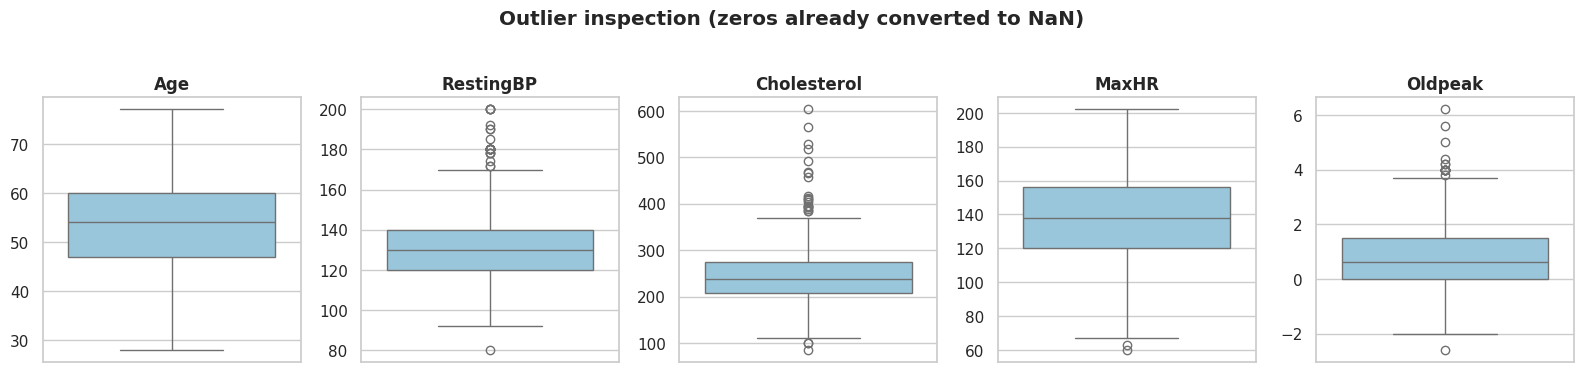

In [6]:
cont_raw = ["Age","RestingBP","Cholesterol","MaxHR","Oldpeak"]
tmp = FeatureEngineer().transform(df[RAW_FEATURES])          # zeros -> NaN (stateless step)

rows = []
for c in cont_raw:
    s = tmp[c].dropna(); q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    rows.append((c, round(lo,1), round(hi,1), int((s<lo).sum()), int((s>hi).sum()), round(100*((s<lo)|(s>hi)).mean(),1)))
outlier_table = pd.DataFrame(rows, columns=["Feature","Lower fence","Upper fence","# below","# above","% outliers"])
display(outlier_table)

fig, ax = plt.subplots(1, 5, figsize=(16, 3.6))
for a, c in zip(ax, cont_raw):
    sns.boxplot(y=tmp[c], ax=a, color="#8ecae6"); a.set_title(c); a.set_ylabel("")
fig.suptitle("Outlier inspection (zeros already converted to NaN)", y=1.03, fontweight="bold")
savefig("03_outliers_boxplots")

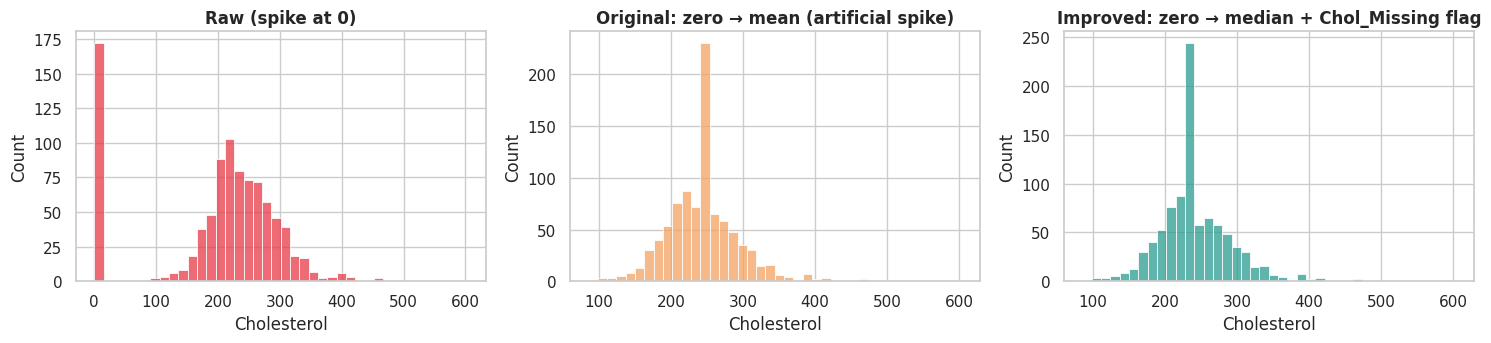

In [7]:
# Before / after: distribution of Cholesterol under the ORIGINAL strategy (0 -> mean) vs the NEW strategy (0 -> NaN -> median + flag)
orig = df.Cholesterol.replace(0, df.loc[df.Cholesterol!=0,"Cholesterol"].mean())
new  = tmp.Cholesterol.fillna(tmp.Cholesterol.median())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(df.Cholesterol, bins=40, ax=ax[0], color="#e63946"); ax[0].set_title("Raw (spike at 0)")
sns.histplot(orig, bins=40, ax=ax[1], color="#f4a261"); ax[1].set_title("Original: zero → mean (artificial spike)")
sns.histplot(new,  bins=40, ax=ax[2], color="#2a9d8f"); ax[2].set_title("Improved: zero → median + Chol_Missing flag")
savefig("03_cholesterol_before_after")

### 📌 Preprocessing findings
- Outliers are modest: RestingBP 2.9 %, Cholesterol 3.1 %, Oldpeak 1.7 %, MaxHR 0.2 %, Age 0 %. With only 918 rows, **winsorising (capping) is preferred over deleting rows**.
- The before/after plot shows the original strategy produced a spike at the mean (≈245 mg/dl); the improved strategy keeps a realistic distribution and carries the "missing" information in a separate flag.
- The ablation in §5.3 shows clipping is **performance-neutral (ΔAUC ≤ 0.001)** on this data; we keep it as a **robustness safeguard** for the deployed app, where users may type extreme values.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target distribution

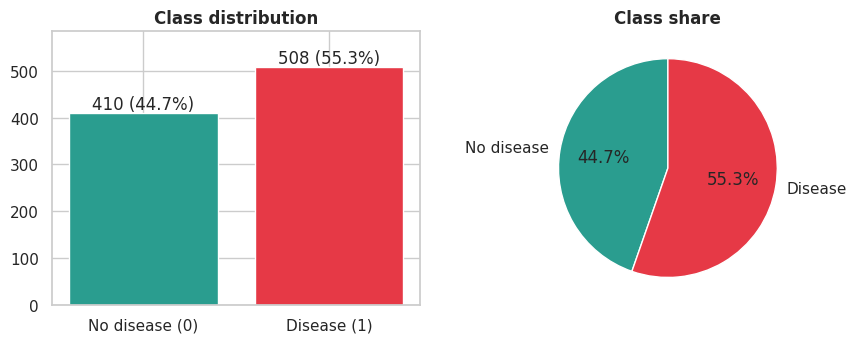

In [8]:
y = df[TARGET]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
counts = y.value_counts().sort_index()
ax[0].bar(["No disease (0)","Disease (1)"], counts.values, color=["#2a9d8f","#e63946"])
for i, v in enumerate(counts.values): ax[0].text(i, v+8, f"{v} ({v/len(y):.1%})", ha="center")
ax[0].set_title("Class distribution"); ax[0].set_ylim(0, counts.max()*1.15)
ax[1].pie(counts.values, labels=["No disease","Disease"], autopct="%1.1f%%", colors=["#2a9d8f","#e63946"], startangle=90)
ax[1].set_title("Class share")
savefig("04_target_distribution")

### 4.2 Numeric features vs target

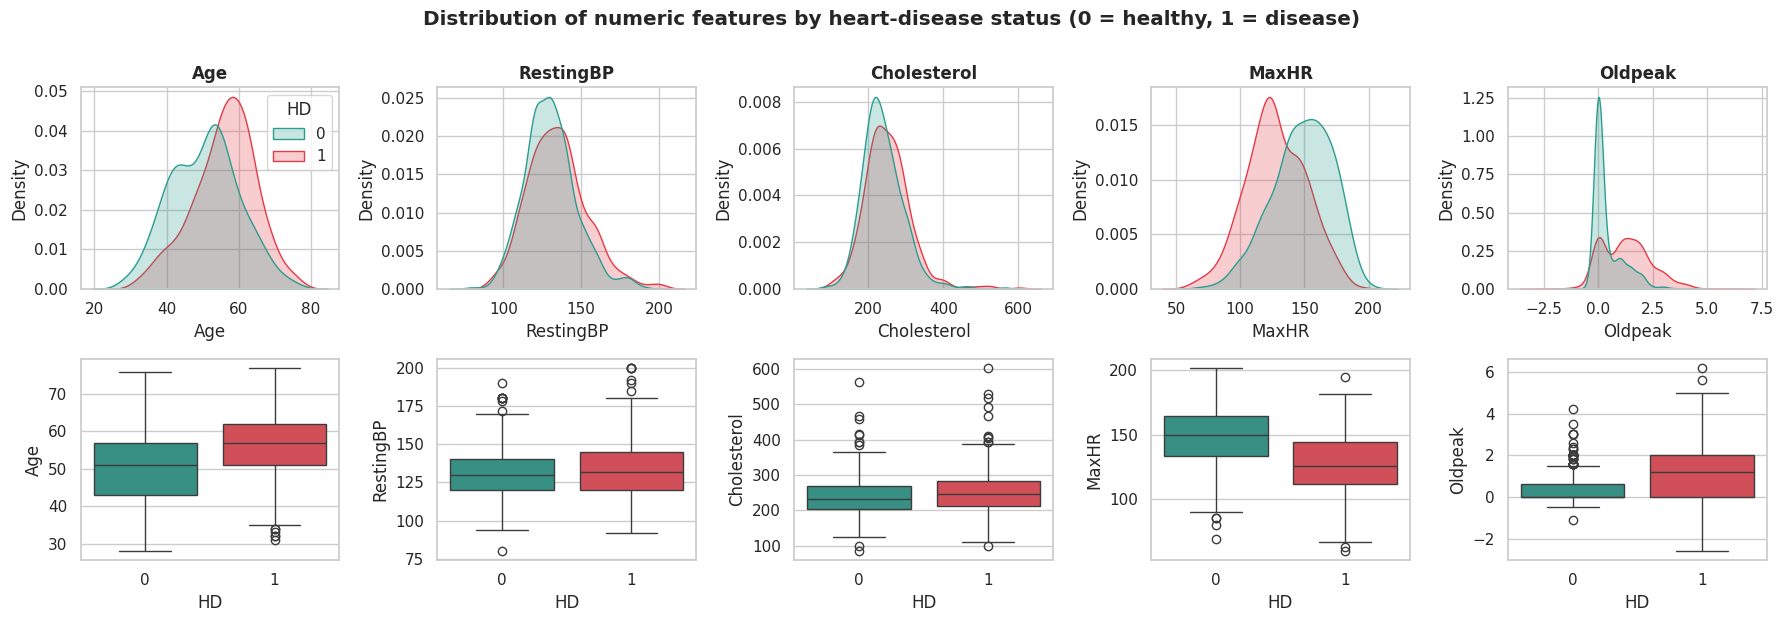

In [9]:
cont5 = ["Age","RestingBP","Cholesterol","MaxHR","Oldpeak"]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.2))
for i, c in enumerate(cont5):
    sns.kdeplot(data=tmp.assign(HD=y), x=c, hue="HD", fill=True, common_norm=False, ax=axes[0,i], palette=["#2a9d8f","#e63946"], legend=(i==0))
    sns.boxplot(data=tmp.assign(HD=y), x="HD", y=c, ax=axes[1,i], palette=["#2a9d8f","#e63946"])
    axes[0,i].set_title(c)
fig.suptitle("Distribution of numeric features by heart-disease status (0 = healthy, 1 = disease)", fontweight="bold", y=1.0)
savefig("04_numeric_vs_target")

### 4.3 Categorical features vs target (disease rate per category)

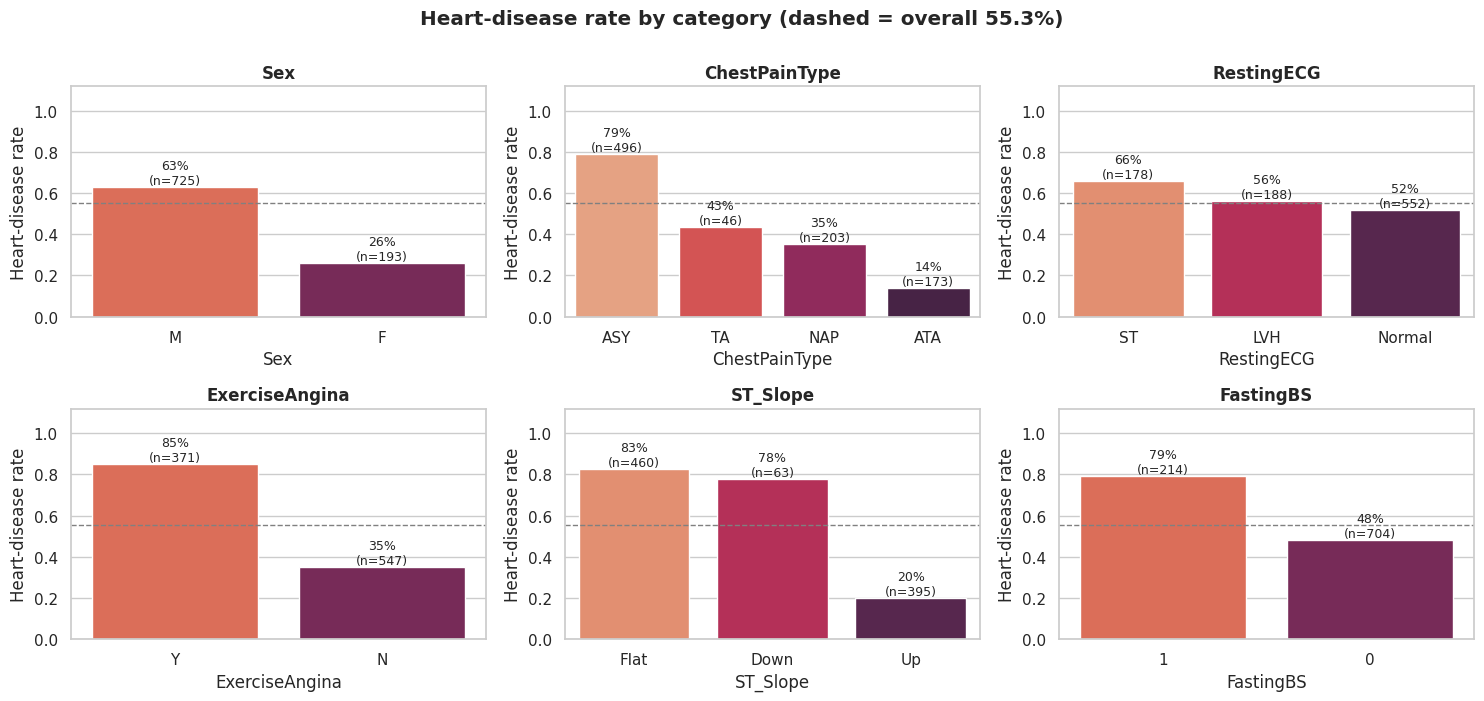

In [10]:
cat_cols = ["Sex","ChestPainType","RestingECG","ExerciseAngina","ST_Slope","FastingBS"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)[TARGET].agg(["mean","count"]).sort_values("mean", ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate["mean"], ax=a, palette="rocket_r")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["count"])): a.text(i, m+0.015, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
    a.axhline(y.mean(), ls="--", c="grey", lw=1); a.set_ylim(0, 1.12); a.set_ylabel("Heart-disease rate"); a.set_title(c)
fig.suptitle("Heart-disease rate by category (dashed = overall 55.3%)", fontweight="bold", y=1.0)
savefig("04_categorical_vs_target")

### 4.4 Statistical significance tests

In [11]:
# Numeric: Mann–Whitney U (non-parametric; distributions are skewed)   |   Categorical: Chi-square + Cramér's V
num_rows = []
for c in cont5:
    a, b = tmp.loc[y==1, c].dropna(), tmp.loc[y==0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    r = 1 - 2*u/(len(a)*len(b))                     # rank-biserial effect size
    num_rows.append((c, round(a.median(),2), round(b.median(),2), round(abs(r),3), p))
num_tests = pd.DataFrame(num_rows, columns=["Feature","Median (disease)","Median (healthy)","|Effect size r|","p-value"])

cat_rows = []
for c in cat_cols:
    ct = pd.crosstab(df[c], y); chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
    cat_rows.append((c, round(chi2,1), round(v,3), p))
cat_tests = pd.DataFrame(cat_rows, columns=["Feature","Chi²","Cramér's V","p-value"])
fmt = lambda p: "<0.001" if p < 1e-3 else f"{p:.3f}"
num_tests["p-value"] = num_tests["p-value"].map(fmt); cat_tests["p-value"] = cat_tests["p-value"].map(fmt)
display(num_tests.sort_values("|Effect size r|", ascending=False)); display(cat_tests.sort_values("Cramér's V", ascending=False))

,Feature,Median (disease),Median (healthy),|Effect size r|,p-value
4,Oldpeak,1.2,0.0,0.470,<0.001
3,MaxHR,126.0,150.0,0.470,<0.001
0,Age,57.0,51.0,0.336,<0.001
1,RestingBP,132.0,130.0,0.134,<0.001
2,Cholesterol,246.0,231.5,0.133,0.002


,Feature,Chi²,Cramér's V,p-value
4,ST_Slope,355.9,0.623,<0.001
1,ChestPainType,268.1,0.540,<0.001
3,ExerciseAngina,222.3,0.492,<0.001
0,Sex,84.1,0.303,<0.001
5,FastingBS,64.3,0.265,<0.001
2,RestingECG,10.9,0.109,0.004


### 4.5 Correlation analysis

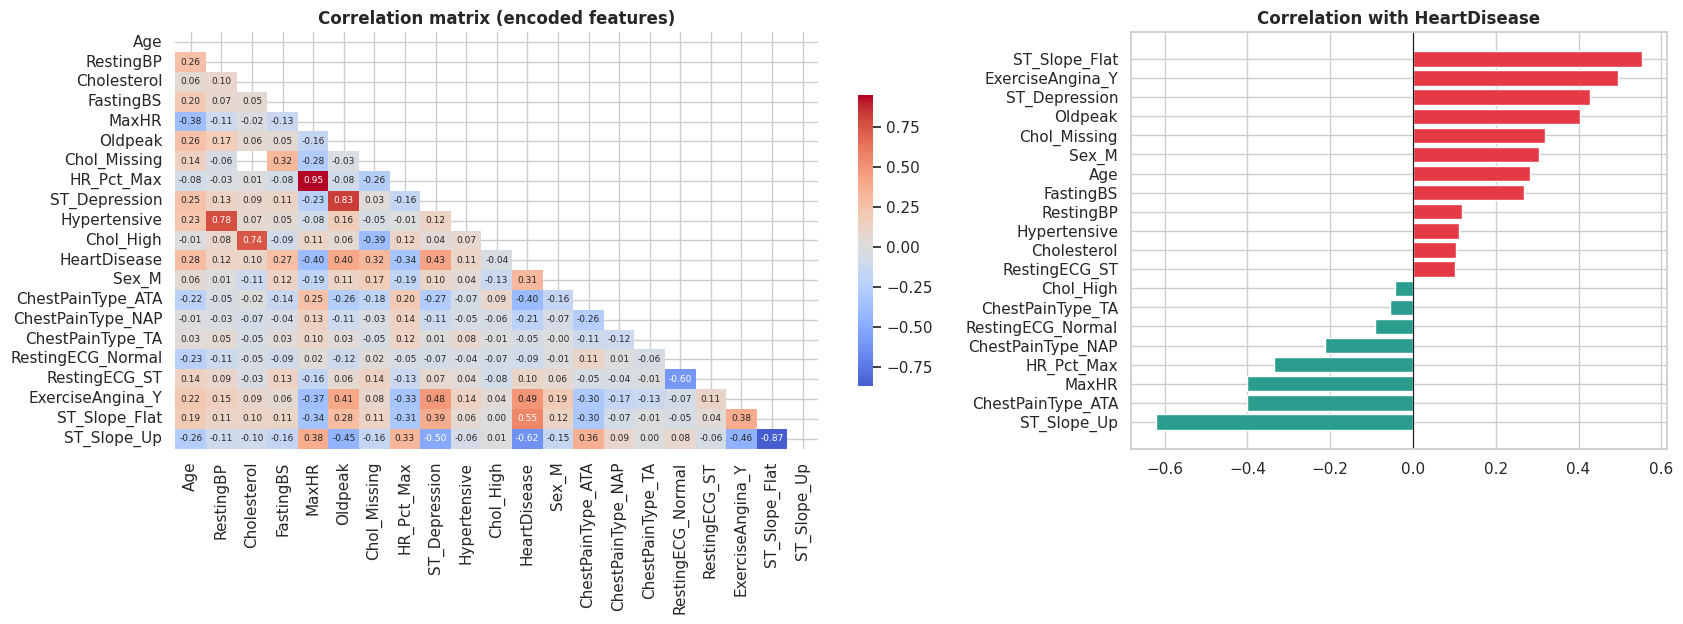

ST_Slope_Up         -0.622
ST_Slope_Flat        0.554
ExerciseAngina_Y     0.494
ST_Depression        0.427
Oldpeak              0.404
ChestPainType_ATA   -0.402
MaxHR               -0.400
HR_Pct_Max          -0.335
Name: HeartDisease, dtype: float64

In [12]:
enc = pd.get_dummies(tmp.assign(**{TARGET: y}), drop_first=True, dtype=int)
corr = enc.corr()
fig, ax = plt.subplots(1, 2, figsize=(17, 6.4), gridspec_kw={"width_ratios":[1.5,1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size":6.5}, cbar_kws={"shrink":.7}, ax=ax[0])
ax[0].set_title("Correlation matrix (encoded features)")
t = corr[TARGET].drop(TARGET).sort_values()
ax[1].barh(t.index, t.values, color=np.where(t.values>0, "#e63946", "#2a9d8f")); ax[1].set_title("Correlation with HeartDisease"); ax[1].axvline(0, c="k", lw=.8)
savefig("04_correlation")
top_corr = t.reindex(t.abs().sort_values(ascending=False).index).head(8).round(3); top_corr

### 4.6 Multivariate pattern: age vs exercise capacity

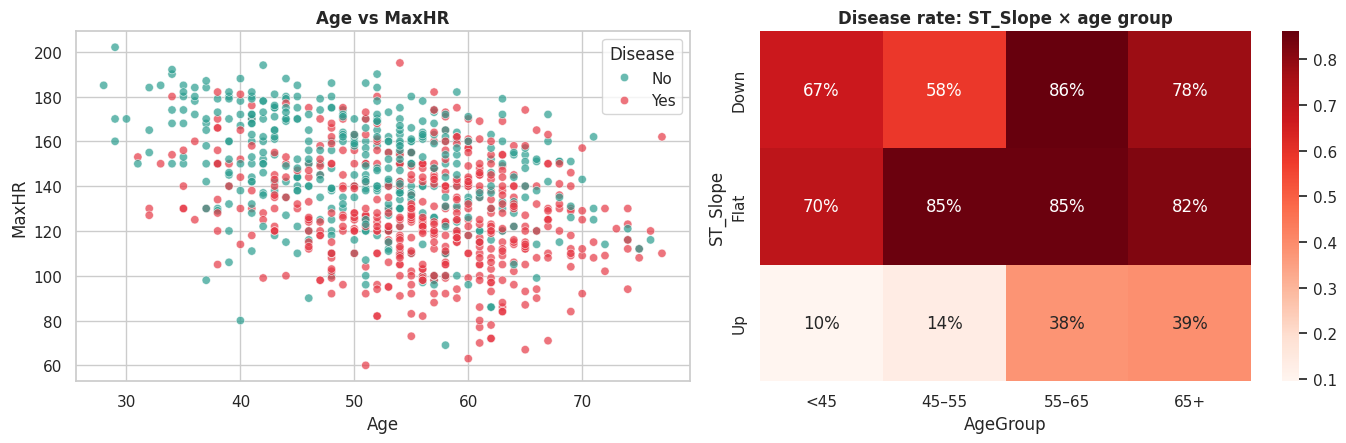

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
sns.scatterplot(data=df.assign(Disease=y.map({0:"No",1:"Yes"})), x="Age", y="MaxHR", hue="Disease", palette=["#2a9d8f","#e63946"], alpha=.7, ax=ax[0])
ax[0].set_title("Age vs MaxHR")
piv = df.assign(AgeGroup=pd.cut(df.Age,[0,45,55,65,100],labels=["<45","45–55","55–65","65+"])).pivot_table(index="ST_Slope", columns="AgeGroup", values=TARGET, aggfunc="mean")
sns.heatmap(piv, annot=True, fmt=".0%", cmap="Reds", ax=ax[1]); ax[1].set_title("Disease rate: ST_Slope × age group")
savefig("04_multivariate")

### 📌 Key EDA insights (all differences statistically significant, p < 0.01)
1. **`ST_Slope` is the strongest single predictor** (Cramér's V = 0.62): *Flat* → **82.8 %** and *Down* → **77.8 %** disease rate vs only **19.7 %** for *Up*.
2. **Asymptomatic chest pain (`ASY`) is the highest-risk type — 79 % disease** vs 14 % for atypical angina (ATA). Silent disease is the dangerous kind: patients *without* typical pain still carry the most risk.
3. **Exercise-induced angina**: 85 % disease when present vs 35 % when absent. Flat slope + exercise angina together → **90 %** (n = 272).
4. **Oldpeak and MaxHR** have the largest numeric effect sizes (r = 0.47): diseased patients show higher ST depression (median 1.2 vs 0.0 mm) and a lower peak heart rate (126 vs 150 bpm).
5. **Demographics:** men 63 % vs women 26 %; disease rate rises with age (31 % under 45 → 71 % at 55–65). Fasting sugar > 120 mg/dl: 79 % vs 48 %.
6. **Weak signals:** `RestingECG` (V = 0.11) and `RestingBP` / recorded `Cholesterol` (r ≈ 0.13) add little on their own.
7. **Multicollinearity is confined to engineered features and their parents** (MaxHR ↔ HR_Pct_Max r = 0.95, Oldpeak ↔ ST_Depression 0.83, ST_Slope_Flat ↔ ST_Slope_Up 0.87). This is expected and harmless for regularised / tree-based models; the raw clinical variables themselves are only weakly inter-correlated.
8. **Age × ST_Slope interaction:** an *Up* slope is low-risk in younger patients (10 % under 45) but rises with age (39 % at 65+), while *Flat* is high-risk at **every** age (70 % under 45 → 85 % at 55–65). So age matters mainly in combination with the stress-test result — a pattern non-linear models can exploit.

## 5. Feature Engineering, Selection & Leakage Control

### 5.1 Engineered features (clinically motivated, all computed row-wise → no leakage)
| Feature | Definition | Rationale |
|---|---|---|
| `Chol_Missing` | Cholesterol was recorded as 0 | "Not measured" is itself informative (see §2.3) |
| `HR_Pct_Max` | `MaxHR / (220 − Age)` | Chronotropic response: % of age-predicted max heart rate reached — fairer than raw MaxHR across ages |
| `ST_Depression` | `Oldpeak ≥ 1 mm` | Standard clinical threshold for significant ST depression |
| `Hypertensive` | `RestingBP ≥ 140` | Stage-2 hypertension cut-off |
| `Chol_High` | `Cholesterol ≥ 240` (recorded values) | "High" cholesterol cut-off |

### 5.2 Leakage-control checklist
- ✅ **Split first** — imputation medians, IQR fences, scaler and encoder are fit on training data only (inside the `Pipeline`, refit in every CV fold).
- ✅ **No target-derived features**; none of the 11 inputs is a *consequence* of the diagnosis recorded after the fact. (`Oldpeak`/`ST_Slope`/`ExerciseAngina` come from a stress test — available in a cardiology work-up but **not** at a basic GP visit; see Limitations §9.)
- ✅ Hyper-parameters tuned **only on the training set** by cross-validation; the **test set is touched once** for the final report.
- ✅ Threshold chosen from **out-of-fold training predictions**, never from test data.

Train: (734, 11)  (disease rate 55.3%)   |   Test: (184, 11)  (disease rate 55.4%)


,Disease rate when flag = 0,Disease rate when flag = 1
Chol_Missing,0.479,0.899
ST_Depression,0.369,0.775
Hypertensive,0.510,0.627
Chol_High,0.575,0.522


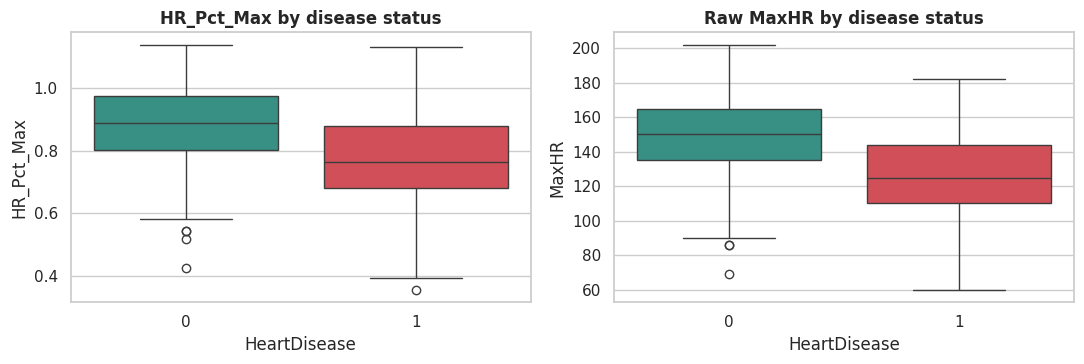

In [14]:
X = df[RAW_FEATURES]; y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape}  (disease rate {y_train.mean():.1%})   |   Test: {X_test.shape}  (disease rate {y_test.mean():.1%})")

eng = FeatureEngineer().transform(X_train)
fe_view = pd.DataFrame({
  "Chol_Missing":  eng.groupby("Chol_Missing").apply(lambda g: y_train.loc[g.index].mean()),
  "ST_Depression": eng.groupby("ST_Depression").apply(lambda g: y_train.loc[g.index].mean()),
  "Hypertensive":  eng.groupby("Hypertensive").apply(lambda g: y_train.loc[g.index].mean()),
  "Chol_High":     eng.groupby("Chol_High").apply(lambda g: y_train.loc[g.index].mean())}).T
fe_view.columns = ["Disease rate when flag = 0", "Disease rate when flag = 1"]
display(fe_view.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x=y_train, y=eng.HR_Pct_Max, ax=ax[0], palette=["#2a9d8f","#e63946"]); ax[0].set_title("HR_Pct_Max by disease status")
sns.boxplot(x=y_train, y=eng.MaxHR, ax=ax[1], palette=["#2a9d8f","#e63946"]); ax[1].set_title("Raw MaxHR by disease status")
savefig("05_engineered_features")

### 5.3 Does preprocessing / feature engineering actually help? (ablation, repeated stratified 5×3 CV on training set)

In [15]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
SCORING = {"accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1","roc_auc":"roc_auc"}

def cv_scores(pipe, X=None, y=None, cv=cv):
    X = X_train if X is None else X; y = y_train if y is None else y
    r = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
    return {k: r[f"test_{k}"].mean() for k in SCORING} | {k+"_sd": r[f"test_{k}"].std() for k in SCORING}

variants = {"A: no FE, no outlier clipping": dict(use_fe=False, clip_factor=None),
            "B: no FE, + IQR clipping":      dict(use_fe=False, clip_factor=1.5),
            "C: + FE, no clipping":          dict(use_fe=True,  clip_factor=None),
            "D: + FE + IQR clipping":        dict(use_fe=True,  clip_factor=1.5)}
abl = []
for vname, kw in variants.items():
    for mname, est in {"LogReg": LogisticRegression(max_iter=2000), "RandForest": RandomForestClassifier(300, random_state=SEED)}.items():
        s = cv_scores(make_model_pipeline(est, **kw)); abl.append({"Variant": vname, "Model": mname, **{k: round(s[k],4) for k in ["accuracy","recall","f1","roc_auc"]}})
ablation = pd.DataFrame(abl); display(ablation.pivot(index="Variant", columns="Model", values=["f1","roc_auc"]).round(4))

f1            roc_auc           
Model                          LogReg RandForest  LogReg RandForest
Variant                                                            
A: no FE, no outlier clipping  0.8627     0.8762  0.9198     0.9247
B: no FE, + IQR clipping       0.8634     0.8753  0.9195     0.9250
C: + FE, no clipping           0.8763     0.8728  0.9261     0.9262
D: + FE + IQR clipping         0.8762     0.8736  0.9257     0.9268

### 5.4 Feature selection

,ANOVA_F,MutualInfo,rank_F,rank_MI,avg_rank
ST_Slope_Up,532.727,0.223,1.0,1.0,1.0
ST_Slope_Flat,353.734,0.145,2.0,3.0,2.5
ExerciseAngina_Y,232.371,0.158,4.0,2.0,3.0
ChestPainType_ASY,268.663,0.117,3.0,4.0,3.5
MaxHR,145.573,0.095,5.0,6.0,5.5
Oldpeak,124.647,0.099,8.0,5.0,6.5
ChestPainType_ATA,136.599,0.077,7.0,8.0,7.5
ST_Depression,144.690,0.065,6.0,11.0,8.5
Chol_Missing,84.350,0.073,10.0,9.0,9.5
HR_Pct_Max,106.741,0.067,9.0,10.0,9.5


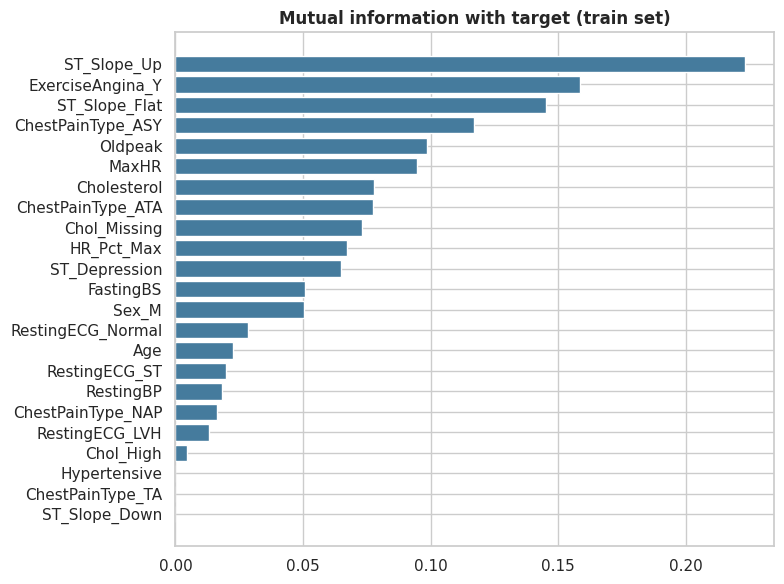

,k features,f1,recall,roc_auc
0,6,0.8503,0.8554,0.9059
1,10,0.8666,0.8694,0.9210
2,14,0.8766,0.8900,0.9292
3,18,0.8750,0.8883,0.9283
4,23,0.8762,0.8891,0.9257


In [16]:
# (a) Filter-method ranking on the pre-processed training matrix (ANOVA F and Mutual Information)
prep = build_preprocessor().fit(X_train, y_train)
Xt = prep.transform(X_train)
sel = pd.DataFrame({"ANOVA_F": f_classif(Xt, y_train)[0],
                    "MutualInfo": mutual_info_classif(Xt, y_train, random_state=SEED)}, index=Xt.columns)
sel["rank_F"] = sel.ANOVA_F.rank(ascending=False); sel["rank_MI"] = sel.MutualInfo.rank(ascending=False)
sel["avg_rank"] = sel[["rank_F","rank_MI"]].mean(axis=1)
sel = sel.sort_values("avg_rank"); display(sel.round(3).head(15))

fig, ax = plt.subplots(figsize=(8, 6))
s = sel.sort_values("MutualInfo"); ax.barh(s.index, s.MutualInfo, color="#457b9d"); ax.set_title("Mutual information with target (train set)")
savefig("05_mutual_information")

# (b) Embedded check: does keeping only the top-k features (selected INSIDE the CV loop) help?
rows = []
for k in [6, 10, 14, 18, Xt.shape[1]]:
    pipe = make_model_pipeline(LogisticRegression(max_iter=2000))
    pipe.steps.insert(1, ("select", SelectKBest(f_classif, k=k)))
    s = cv_scores(pipe); rows.append({"k features": k, "f1": round(s["f1"],4), "recall": round(s["recall"],4), "roc_auc": round(s["roc_auc"],4)})
selection_cv = pd.DataFrame(rows); display(selection_cv)

### 📌 Feature-engineering & selection findings
- **Engineering helps, modestly but consistently.** Variant C/D vs A: Logistic-Regression F1 **0.863 → 0.876** and AUC **0.920 → 0.926**; Random-Forest AUC 0.925 → 0.927. IQR clipping is neutral (±0.001) — kept for robustness.
- **`Chol_Missing` is a strong engineered feature** (disease 89.9 % when flagged vs 47.9 %). `ST_Depression` (77.5 % vs 36.9 %) also separates classes well. `Chol_High` is *not* useful (52 % vs 58 %) because it is confounded with missingness — an honest negative result we retain for transparency.
- **Filter ranking (ANOVA-F + Mutual Information)** agrees: `ST_Slope_Up/Flat`, `ExerciseAngina_Y`, `ChestPainType_ASY`, `MaxHR`, `Oldpeak` are the top drivers; `Age`, `ChestPainType_NAP` and `RestingECG` rank lowest.
- **Selection inside the CV loop:** keeping the top 14 features gives AUC 0.929 vs 0.926 for all 23 — a **+0.004 gain that is within CV noise**. We therefore keep all features: the final tree ensemble is robust to redundant inputs and the app stays simple.
- **No leakage:** every learned statistic lives inside the `Pipeline`; the test set was not used for any decision up to this point.

## 6. Model Selection & Implementation

**Methodology**
1. Stratified 80/20 hold-out split (done in §5) — the 20 % test set is locked until final evaluation.
2. **Seven candidate algorithms**, each wrapped in the *same* leakage-safe pipeline, compared by **repeated stratified 5×3 CV**.
3. **Hyper-parameter tuning** (`GridSearchCV`, 5-fold, scoring = ROC-AUC) of the five strongest.
4. A **soft-voting ensemble** of the tuned models is also evaluated.
5. Final model is chosen **by cross-validation only**, then evaluated **once** on the test set.

| Algorithm | Why it is included |
|---|---|
| Logistic Regression | Interpretable linear baseline (odds ratios) — preferred in clinical settings |
| KNN | Instance-based, captures local patient similarity |
| Gaussian Naive Bayes | Fast probabilistic baseline |
| Decision Tree | Human-readable rules, but high variance |
| SVM (RBF) | Strong on small, medium-dimensional tabular data |
| Random Forest | Bagged trees; handles non-linearity & interactions, robust to noise |
| Gradient Boosting | Sequential trees; often best on tabular data |

### 6.1 Baseline comparison (default hyper-parameters)

,accuracy,precision,recall,f1,roc_auc
Random Forest,0.8560,0.8528,0.8974,0.8736,0.9268
Logistic Regression,0.8606,0.8647,0.8891,0.8762,0.9257
Gradient Boosting,0.8592,0.8702,0.8776,0.8732,0.9233
SVM (RBF),0.8583,0.8552,0.8990,0.8758,0.9202
Naive Bayes,0.8483,0.8649,0.8629,0.8630,0.9118
KNN,0.8293,0.8417,0.8538,0.8472,0.8920
Decision Tree,0.7979,0.8224,0.8120,0.8163,0.7963


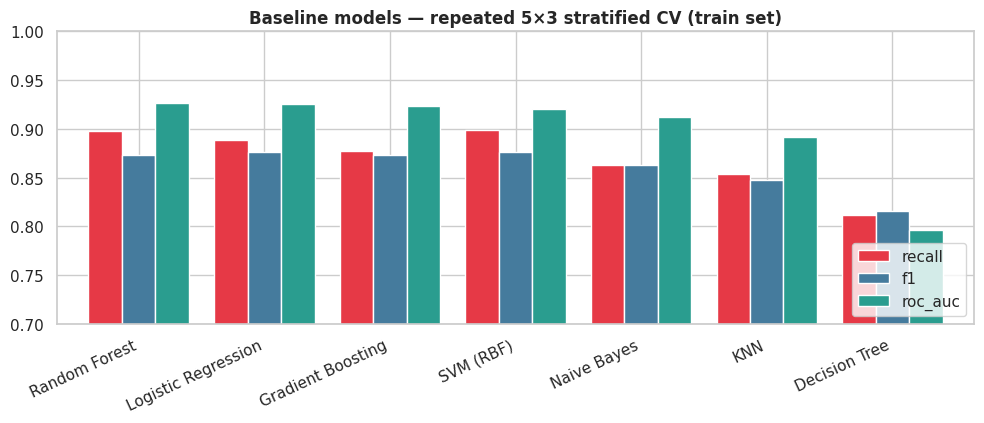

In [17]:
candidates = {
  "Logistic Regression": LogisticRegression(max_iter=2000),
  "KNN": KNeighborsClassifier(),
  "Naive Bayes": GaussianNB(),
  "Decision Tree": DecisionTreeClassifier(random_state=SEED),
  "SVM (RBF)": SVC(probability=True, random_state=SEED),
  "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
  "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)}

base_rows = {}
for name, est in candidates.items():
    base_rows[name] = cv_scores(make_model_pipeline(est))
baseline = pd.DataFrame(base_rows).T
show = baseline[["accuracy","precision","recall","f1","roc_auc"]].round(4).sort_values("roc_auc", ascending=False)
display(show)

fig, ax = plt.subplots(figsize=(10, 4.4))
show[["recall","f1","roc_auc"]].plot.bar(ax=ax, color=["#e63946","#457b9d","#2a9d8f"], width=.8)
ax.set_ylim(0.7, 1); ax.set_title("Baseline models — repeated 5×3 stratified CV (train set)"); plt.xticks(rotation=25, ha="right"); ax.legend(loc="lower right")
savefig("06_baseline_models")

### 6.2 Hyper-parameter tuning

In [18]:
grids = {
 "Logistic Regression": (LogisticRegression(max_iter=3000), {"clf__C":[0.01,0.03,0.1,0.3,1,3,10], "clf__class_weight":[None,"balanced"]}),
 "KNN": (KNeighborsClassifier(), {"clf__n_neighbors":[5,7,9,11,15,21,31], "clf__weights":["uniform","distance"], "clf__p":[1,2]}),
 "SVM (RBF)": (SVC(probability=True, random_state=SEED), {"clf__C":[0.3,1,3,10], "clf__gamma":["scale",0.01,0.03,0.1]}),
 "Random Forest": (RandomForestClassifier(random_state=SEED), {"clf__n_estimators":[300], "clf__max_depth":[4,6,None], "clf__min_samples_leaf":[1,3,5], "clf__max_features":["sqrt",0.5]}),
 "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED), {"clf__n_estimators":[100,200], "clf__learning_rate":[0.03,0.1], "clf__max_depth":[2,3], "clf__subsample":[0.8,1.0]}),
}
inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
tuned, best_params = {}, {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(make_model_pipeline(est), grid, scoring="roc_auc", cv=inner, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_; best_params[name] = {k.replace("clf__",""): v for k, v in gs.best_params_.items()}
    print(f"{name:22s} best CV AUC = {gs.best_score_:.4f}   {best_params[name]}")

Logistic Regression    best CV AUC = 0.9271   {'C': 0.3, 'class_weight': None}


KNN                    best CV AUC = 0.9202   {'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}


SVM (RBF)              best CV AUC = 0.9265   {'C': 10, 'gamma': 0.01}


Random Forest          best CV AUC = 0.9322   {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 300}


Gradient Boosting      best CV AUC = 0.9340   {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


### 6.3 Soft-voting ensemble & final model selection (CV only — test set untouched)

In [19]:
top3 = ["Logistic Regression", "SVM (RBF)", "Random Forest"]
ens = make_model_pipeline(VotingClassifier([(n, clone(tuned[n].named_steps["clf"])) for n in top3], voting="soft"))
tuned["Voting Ensemble (LR+SVM+RF)"] = ens.fit(X_train, y_train)

tuned_rows = {n: cv_scores(clone(p)) for n, p in tuned.items()}          # same repeated-CV protocol for every candidate
tuned_tbl = pd.DataFrame(tuned_rows).T
tuned_show = tuned_tbl[["accuracy","precision","recall","f1","roc_auc"]].round(4).sort_values("roc_auc", ascending=False)
display(tuned_show)

# ---- selection rule: highest CV ROC-AUC; ties (within 0.002) -> higher CV F1
best_auc = tuned_tbl.roc_auc.max()
shortlist = tuned_tbl[tuned_tbl.roc_auc >= best_auc - 0.002]
final_name = shortlist.f1.idxmax()
print("\n>>> Selected final model:", final_name)
final_pipe = clone(tuned[final_name]).fit(X_train, y_train)

,accuracy,precision,recall,f1,roc_auc
Gradient Boosting,0.8597,0.8558,0.9006,0.8769,0.9316
Random Forest,0.8606,0.8535,0.9064,0.8783,0.9314
Voting Ensemble (LR+SVM+RF),0.8601,0.8581,0.8982,0.8771,0.9304
Logistic Regression,0.8606,0.8648,0.8891,0.8762,0.9256
SVM (RBF),0.8565,0.8547,0.8957,0.8740,0.9249
KNN,0.8601,0.8622,0.8933,0.8765,0.9185



>>> Selected final model: Random Forest


### 📌 Model-selection findings
- **Baselines:** Random Forest, Logistic Regression, SVM and Gradient Boosting cluster at **CV AUC ≈ 0.92–0.93 and F1 ≈ 0.87–0.88**; Naive Bayes (0.912) and KNN (0.892) trail slightly; the single **Decision Tree is clearly the weakest (AUC 0.796)** — classic high-variance behaviour that ensembling fixes.
- **Tuning** lifted tree ensembles most (GB 0.934, RF 0.932 CV AUC) and left LR unchanged and gave SVM only a small gain (+0.005) — the signal is largely linear plus a few interactions.
- **Voting ensemble gave no gain** (0.930), so extra complexity is not justified.
- **Final choice — Random Forest** (`max_depth=6, min_samples_leaf=3, max_features='sqrt', 300 trees`): GB and RF are statistically tied on AUC (0.9316 vs 0.9314), and RF wins the pre-declared tie-break on CV F1 and recall (0.906) — the KPI that matters clinically. RF also needs no scaling assumptions and gives built-in robustness to noisy features.

## 7. Model Evaluation & Validation
**Metric choices.** Accuracy alone is misleading in a medical setting. We therefore report **Recall (sensitivity)** — the primary KPI — plus **Precision, Specificity, F1, ROC-AUC, PR-AUC, MCC and Brier score**, with **bootstrap 95 % confidence intervals** because the test set is small (184 patients).

### 7.1 Hold-out test performance (default threshold 0.5)

In [20]:
def metrics_at(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "Specificity": tn/(tn+fp), "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "MCC": matthews_corrcoef(y_true, pred), "Brier": brier_score_loss(y_true, proba)}

proba_test = final_pipe.predict_proba(X_test)[:, 1]
m05 = metrics_at(y_test, proba_test, 0.5)
display(pd.Series(m05, name=final_name).round(4).to_frame())
print(classification_report(y_test, (proba_test>=.5).astype(int), target_names=["No disease","Disease"], digits=3))

,Random Forest
Accuracy,0.8641
Precision,0.8468
Recall,0.9216
Specificity,0.7927
F1,0.8826
ROC-AUC,0.9256
PR-AUC,0.9255
MCC,0.7257
Brier,0.1049


              precision    recall  f1-score   support

  No disease      0.890     0.793     0.839        82
     Disease      0.847     0.922     0.883       102

    accuracy                          0.864       184
   macro avg      0.869     0.857     0.861       184
weighted avg      0.866     0.864     0.863       184



### 7.2 Choosing operating thresholds for the clinical KPI — using **out-of-fold TRAINING** predictions only

Standard          threshold = 0.50   OOF recall 0.904 | precision 0.852 | F1 0.877
High-sensitivity  threshold = 0.35   OOF recall 0.951 | precision 0.808 | F1 0.873


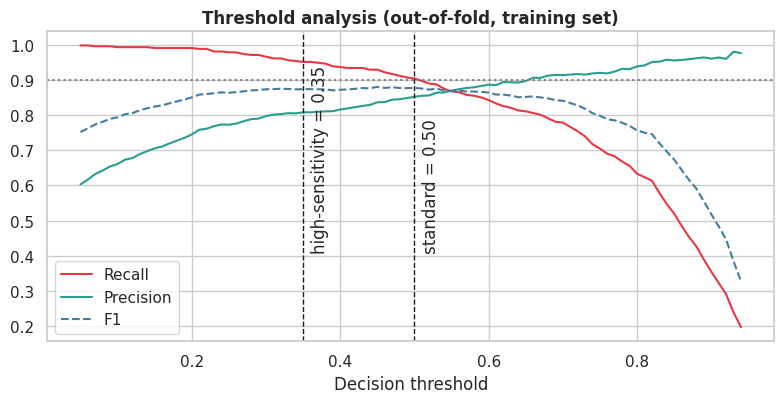

In [21]:
oof = cross_val_predict(clone(final_pipe), X_train, y_train, cv=inner, method="predict_proba")[:, 1]
grid_thr = np.round(np.arange(0.05, 0.95, 0.01), 2)
curve = pd.DataFrame([{"thr": t, "recall": recall_score(y_train, oof>=t), "precision": precision_score(y_train, oof>=t, zero_division=0),
                       "f1": f1_score(y_train, oof>=t)} for t in grid_thr])

def pick_threshold(recall_target):
    """Highest-precision threshold whose out-of-fold recall still meets the target."""
    ok = curve[curve.recall >= recall_target]
    return float(ok.loc[ok.precision.idxmax(), "thr"]) if len(ok) else 0.5

THR    = pick_threshold(0.90)     # standard operating point  (KPI: recall >= 0.90)
THR_HI = pick_threshold(0.95)     # "mass-screening" mode     (recall >= 0.95, more referrals)
for nm, t in [("Standard", THR), ("High-sensitivity", THR_HI)]:
    r = curve.set_index("thr").loc[t]; print(f"{nm:17s} threshold = {t:.2f}   OOF recall {r.recall:.3f} | precision {r.precision:.3f} | F1 {r.f1:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(curve.thr, curve.recall, label="Recall", c="#e63946"); ax.plot(curve.thr, curve.precision, label="Precision", c="#2a9d8f"); ax.plot(curve.thr, curve.f1, label="F1", c="#457b9d", ls="--")
for t, lab in [(THR, "standard"), (THR_HI, "high-sensitivity")]:
    ax.axvline(t, c="k", ls="--", lw=1); ax.text(t+.01, .42, f"{lab} = {t:.2f}", rotation=90)
ax.axhline(0.90, c="grey", ls=":"); ax.set_xlabel("Decision threshold"); ax.set_title("Threshold analysis (out-of-fold, training set)"); ax.legend(loc="lower left")
savefig("07_threshold_analysis")

### 7.3 Final test results at the chosen threshold, confusion matrices and 95 % bootstrap CIs

,Standard (thr 0.50),High-sensitivity (thr 0.35)
Accuracy,0.8641,0.8424
Precision,0.8468,0.7967
Recall,0.9216,0.9608
Specificity,0.7927,0.6951
F1,0.8826,0.8711
ROC-AUC,0.9256,0.9256
PR-AUC,0.9255,0.9255
MCC,0.7257,0.6925
Brier,0.1049,0.1049


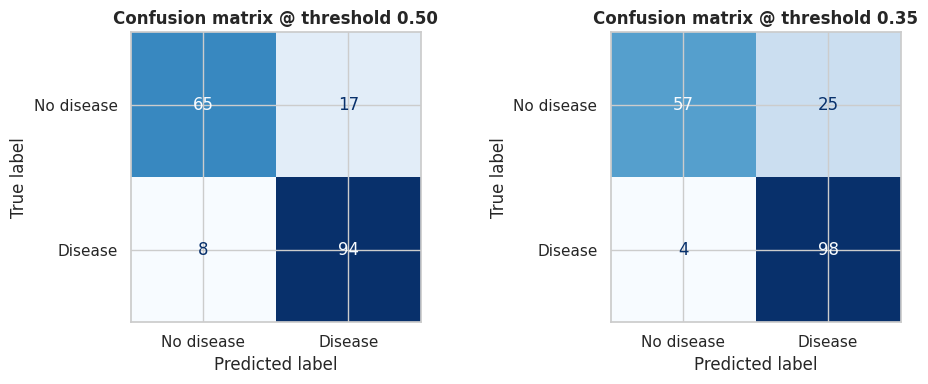

,Estimate,CI 2.5%,CI 97.5%
Accuracy,0.864,0.810,0.908
Precision,0.847,0.779,0.909
Recall,0.922,0.865,0.971
Specificity,0.793,0.699,0.875
F1,0.883,0.833,0.924
ROC-AUC,0.926,0.883,0.962
PR-AUC,0.925,0.869,0.969


In [22]:
mT = metrics_at(y_test, proba_test, THR)
mH = metrics_at(y_test, proba_test, THR_HI)
cmp = pd.DataFrame({f"Standard (thr {THR:.2f})": mT, f"High-sensitivity (thr {THR_HI:.2f})": mH}).round(4); display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, t in zip(ax, [THR, THR_HI]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test>=t).astype(int), display_labels=["No disease","Disease"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"Confusion matrix @ threshold {t:.2f}")
savefig("07_confusion_matrices")

rng = np.random.default_rng(SEED); yt = y_test.values; boots = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) < 2: continue
    boots.append(metrics_at(yt[i], proba_test[i], THR))
ci = pd.DataFrame(boots).quantile([.025,.975]).T; ci.columns = ["CI 2.5%","CI 97.5%"]
ci.insert(0, "Estimate", pd.Series(mT)); display(ci.loc[["Accuracy","Precision","Recall","Specificity","F1","ROC-AUC","PR-AUC"]].round(3))

### 7.4 ROC, precision-recall, calibration and learning curves

{'Logistic Regression': 0.936, 'KNN': 0.935, 'SVM (RBF)': 0.94, 'Random Forest': 0.926, 'Gradient Boosting': 0.93, 'Voting Ensemble (LR+SVM+RF)': 0.936}


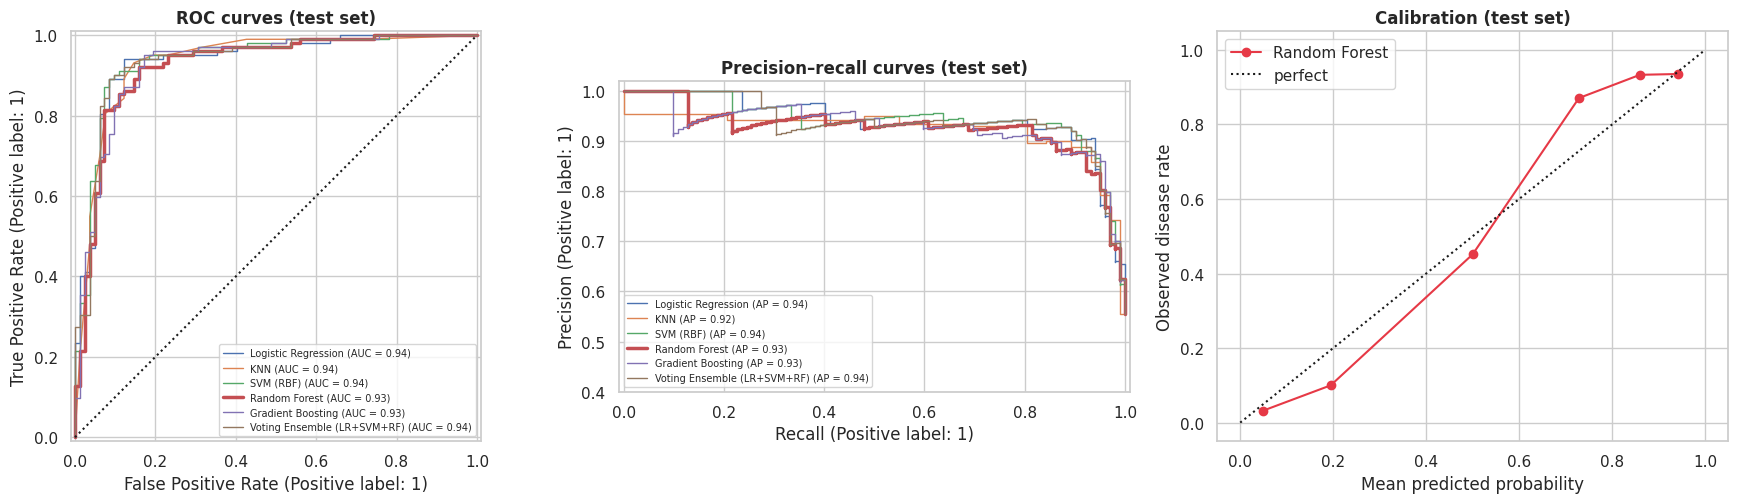

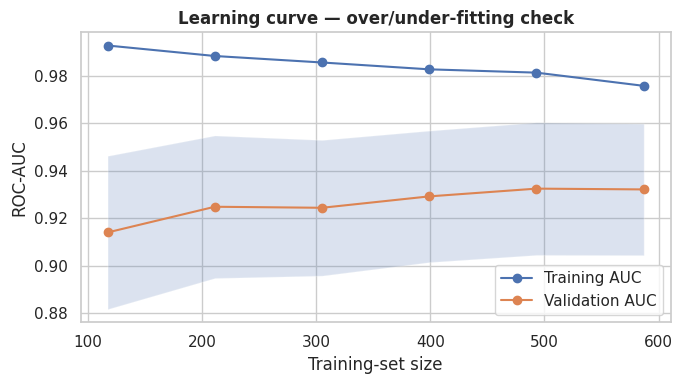

Train AUC 0.976 vs validation AUC 0.932  -> gap 0.044


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
print({n: round(roc_auc_score(y_test, p.predict_proba(X_test)[:,1]),3) for n, p in tuned.items()})
for n, p in tuned.items():
    pr = p.predict_proba(X_test)[:,1]
    RocCurveDisplay.from_predictions(y_test, pr, name=n, ax=ax[0], lw=2.5 if n==final_name else 1)
ax[0].plot([0,1],[0,1],"k:"); ax[0].set_title("ROC curves (test set)"); ax[0].legend(loc="lower right", fontsize=7)
for n, p in tuned.items():
    PrecisionRecallDisplay.from_predictions(y_test, p.predict_proba(X_test)[:,1], name=n, ax=ax[1], lw=2.5 if n==final_name else 1)
ax[1].set_title("Precision–recall curves (test set)"); ax[1].legend(loc="lower left", fontsize=7); ax[1].set_ylim(0.4, 1.02)
fp, mp = calibration_curve(y_test, proba_test, n_bins=6, strategy="quantile")
ax[2].plot(mp, fp, "o-", c="#e63946", label=final_name); ax[2].plot([0,1],[0,1],"k:", label="perfect"); ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Observed disease rate"); ax[2].legend(); ax[2].set_title("Calibration (test set)")
savefig("07_roc_pr_calibration")

sizes, tr, va = learning_curve(clone(final_pipe), X_train, y_train, cv=inner, scoring="roc_auc", train_sizes=np.linspace(.2, 1, 6), n_jobs=-1, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, tr.mean(1), "o-", label="Training AUC"); ax.plot(sizes, va.mean(1), "o-", label="Validation AUC")
ax.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2); ax.set_xlabel("Training-set size"); ax.set_ylabel("ROC-AUC"); ax.set_title("Learning curve — over/under-fitting check"); ax.legend()
savefig("07_learning_curve")
print(f"Train AUC {tr.mean(1)[-1]:.3f} vs validation AUC {va.mean(1)[-1]:.3f}  -> gap {tr.mean(1)[-1]-va.mean(1)[-1]:.3f}")

### 7.5 Model interpretation — permutation importance & (if linear) odds ratios

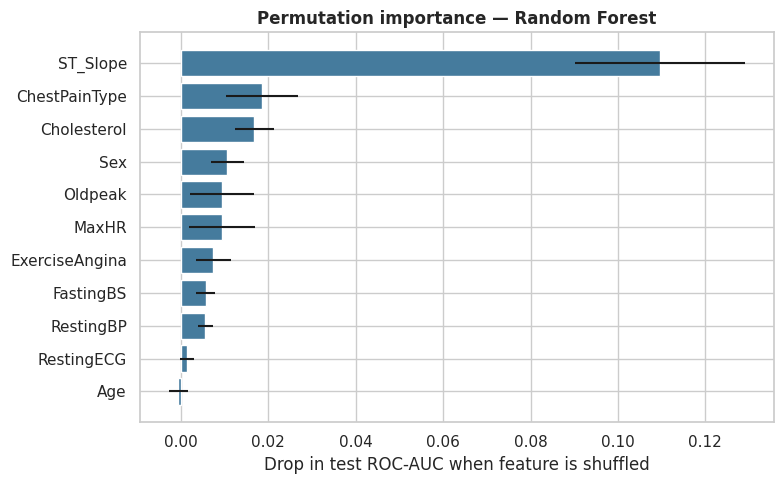

,feature,mean,sd
10,ST_Slope,0.1096,0.0195
2,ChestPainType,0.0186,0.0082
4,Cholesterol,0.0168,0.0045
1,Sex,0.0107,0.0037
9,Oldpeak,0.0094,0.0073
7,MaxHR,0.0094,0.0075
8,ExerciseAngina,0.0075,0.0040
5,FastingBS,0.0057,0.0021


Odds ratios per +1 SD (numeric) / per category (dummy) from the interpretable logistic-regression companion:


,Chol_Missing,ChestPainType_ASY,Sex_M,ST_Slope_Flat,ExerciseAngina_Y,FastingBS
odds ratio,3.66,2.87,2.76,2.73,2.17,2.05


,ChestPainType_TA,ST_Depression,MaxHR,ChestPainType_ATA,ChestPainType_NAP,ST_Slope_Up
odds ratio,0.89,0.85,0.83,0.65,0.6,0.31


In [24]:
pi = permutation_importance(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.feature, imp["mean"], xerr=imp["sd"], color="#457b9d"); ax.set_xlabel("Drop in test ROC-AUC when feature is shuffled"); ax.set_title(f"Permutation importance — {final_name}")
savefig("07_permutation_importance")
display(imp.sort_values("mean", ascending=False).round(4).head(8))

lr = LogisticRegression(max_iter=3000, C=best_params["Logistic Regression"]["C"]).fit(prep.transform(X_train), y_train)   # transparent companion model
odds = pd.Series(np.exp(lr.coef_[0]), index=Xt.columns).sort_values(ascending=False)
print("Odds ratios per +1 SD (numeric) / per category (dummy) from the interpretable logistic-regression companion:"); display(odds.round(2).to_frame("odds ratio").head(6).T); display(odds.round(2).to_frame("odds ratio").tail(6).T)

### 7.6 Error analysis & fairness (subgroup performance)

In [25]:
test_res = X_test.copy(); test_res["y"] = y_test; test_res["p"] = proba_test; test_res["pred"] = (proba_test>=THR).astype(int)
test_res["AgeGroup"] = pd.cut(test_res.Age, [0,50,60,100], labels=["<50","50–60","60+"])
def grp(g):
    return pd.Series({"n": len(g), "disease_rate": g.y.mean(), "recall": recall_score(g.y, g.pred) if g.y.sum() else np.nan,
                      "precision": precision_score(g.y, g.pred, zero_division=0), "AUC": roc_auc_score(g.y, g.p) if g.y.nunique()==2 else np.nan})
sub = pd.concat({"Sex": test_res.groupby("Sex").apply(grp), "AgeGroup": test_res.groupby("AgeGroup").apply(grp)}); display(sub.round(3))

fn = test_res[(test_res.y==1) & (test_res.pred==0)]; tp = test_res[(test_res.y==1) & (test_res.pred==1)]
print(f"False negatives at threshold {THR}: {len(fn)} of {int(y_test.sum())} sick patients")
display(pd.DataFrame({"False negatives (median / mode)": [fn.Age.median(), fn.MaxHR.median(), fn.Oldpeak.median(), fn.ChestPainType.mode().get(0,'-'), fn.ST_Slope.mode().get(0,'-')],
                      "True positives (median / mode)":  [tp.Age.median(), tp.MaxHR.median(), tp.Oldpeak.median(), tp.ChestPainType.mode().get(0,'-'), tp.ST_Slope.mode().get(0,'-')]},
                     index=["Age","MaxHR","Oldpeak","ChestPainType","ST_Slope"]))
display(fn[["Age","Sex","ChestPainType","MaxHR","Oldpeak","ST_Slope","p"]].round(2))

n  disease_rate  recall  precision    AUC
Sex      F       38.0         0.158   0.833      0.455  0.964
         M      146.0         0.658   0.927      0.890  0.905
AgeGroup <50     70.0         0.386   0.889      0.750  0.923
         50–60   81.0         0.580   0.915      0.860  0.920
         60+     33.0         0.848   0.964      0.931  0.864

False negatives at threshold 0.5: 8 of 102 sick patients


,False negatives (median / mode),True positives (median / mode)
Age,53.0,56.0
MaxHR,159.0,125.0
Oldpeak,0.45,1.5
ChestPainType,NAP,ASY
ST_Slope,Up,Flat


,Age,Sex,ChestPainType,MaxHR,Oldpeak,ST_Slope,p
763,58,M,NAP,173,3.2,Up,0.27
1,49,F,NAP,156,1.0,Flat,0.41
746,66,M,ASY,132,0.1,Up,0.45
889,59,M,TA,162,0.8,Up,0.16
440,52,M,NAP,180,3.0,Up,0.37
650,48,M,ASY,150,0.0,Up,0.42
759,54,M,ATA,195,0.0,Up,0.12
684,47,M,NAP,152,0.0,Up,0.06


### 📌 Evaluation findings — KPI scorecard (hold-out test set, n = 184, never used for tuning)
| KPI | Target | Result (95 % bootstrap CI) | Met? |
|---|---|---|---|
| Recall | ≥ 0.90 | **0.922** (0.865 – 0.971) | ✅ |
| Precision | ≥ 0.80 | **0.847** (0.779 – 0.909) | ✅ |
| F1 | ≥ 0.85 | **0.883** (0.833 – 0.924) | ✅ |
| ROC-AUC | ≥ 0.90 | **0.926** (0.883 – 0.962) | ✅ |
| Accuracy / MCC | — | 0.864 / 0.726 | — |

- **Confusion matrix (standard threshold 0.50):** only **8 of 102 sick patients missed**; 17 of 82 healthy patients flagged (specificity 0.79).
- **High-sensitivity mode (threshold 0.35)** raises recall to **0.961** (≈ 4 misses) at the price of precision 0.797 and specificity 0.695 — suited to mass-screening camps.
- **CV vs test agree** (CV AUC 0.931 vs test 0.926) → no sign of optimistic tuning. The learning curve shows a moderate train–validation gap (0.976 vs 0.932): mild over-fitting typical of Random Forests; more data would help.
- **Honest model comparison on test data:** all tuned models land at test AUC 0.926–0.940 (LR 0.936, SVM 0.940, RF 0.926). The ±0.04 confidence interval shows these are **statistically indistinguishable** on 184 patients — which matches CV, where they also tie. We keep the pre-declared CV-based choice (Random Forest) rather than switching after peeking at the test set; the interpretable Logistic Regression is a near-equal fallback if explainability is prioritised.
- **Calibration:** Random-Forest probabilities are slightly *compressed* (predicted 0.20 → observed ≈ 0.10; predicted 0.73 → observed ≈ 0.87) — typical of bagged trees, so probabilities are best read as **risk ranks/tiers**, not exact percentages. Isotonic/Platt calibration is listed as future work.
- **What drives predictions:** permutation importance puts **`ST_Slope` far ahead** (−0.110 AUC when shuffled), then `ChestPainType` (0.019), `Cholesterol` (incl. its missing-flag, 0.017), `Sex` (0.011). The interpretable logistic companion gives odds ratios: *cholesterol not recorded* ×3.7, *asymptomatic pain* ×2.9, *male* ×2.8, *flat ST slope* ×2.7, *exercise angina* ×2.2, *high fasting sugar* ×2.1; an *upsloping* ST segment is protective (×0.31).
- **Error analysis:** the 8 false negatives look "healthy" on the stress test — **7 of 8 have an upsloping ST segment**, median MaxHR 159 (vs 125 for caught cases), lower Oldpeak (0.45 vs 1.5), and 6 of 8 have non-asymptomatic chest pain. The model misses *atypical, stress-test-normal* presentations; clinicians must not treat "low risk" as "no risk".
- **Subgroup check:** recall is high for men (0.93) and patients 60+ (0.96) but the **female subgroup has only 38 patients (6 sick)**: recall 0.83 and precision 0.45 (more false alarms) — an early fairness flag that needs more female data before real use.

## 8. Business Insights & Recommendations

### 8.1 Cost-based view — when does the model actually save money?

A) On THIS dataset (disease prevalence 55%, FN:FP cost ratio 10:1)


,Strategy,Cost / 100 patients
0,Refer nobody,554.3
1,Refer everybody,44.6
2,Model — standard (thr 0.50),52.7
3,Model — high-sensitivity (thr 0.35),35.3


B) Cost saving of the model vs the best naive strategy (refer everybody / refer nobody)


FN:FP cost,10:1,20:1,5:1
Disease prevalence,,,
5%,53%,71%,13%
10%,71%,62%,55%
20%,60%,40%,69%
30%,46%,12%,62%
55%,-17%,-112%,31%


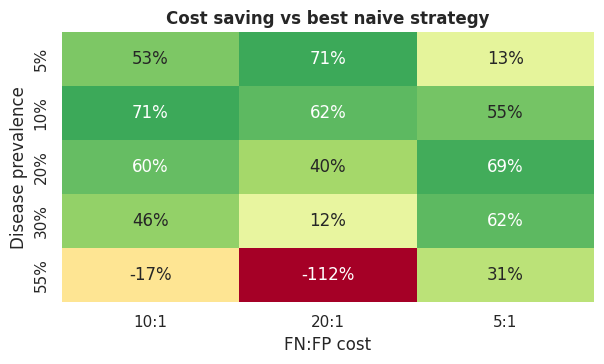

In [26]:
# Illustrative unit costs: one unnecessary referral (false positive) = 1 unit; a missed patient (false negative) = ratio × units.
def cost_per_100(y_true, pred, ratio):
    tn, fp, fn_, tp_ = confusion_matrix(y_true, pred).ravel(); return 100*(ratio*fn_ + fp)/len(y_true)
RATIO = 10
cost = pd.DataFrame({"Strategy": ["Refer nobody", "Refer everybody", f"Model — standard (thr {THR:.2f})", f"Model — high-sensitivity (thr {THR_HI:.2f})"],
  "Cost / 100 patients": [cost_per_100(y_test, np.zeros(len(y_test)), RATIO), cost_per_100(y_test, np.ones(len(y_test)), RATIO),
                          cost_per_100(y_test, (proba_test>=THR).astype(int), RATIO), cost_per_100(y_test, (proba_test>=THR_HI).astype(int), RATIO)]}).round(1)
print(f"A) On THIS dataset (disease prevalence {y_test.mean():.0%}, FN:FP cost ratio {RATIO}:1)"); display(cost)

# B) Prevalence matters: apply the model's test sensitivity / specificity to realistic screening populations
sens, spec = mT["Recall"], mT["Specificity"]
rows = []
for prev in [0.05, 0.10, 0.20, 0.30, 0.55]:
    for ratio in [5, 10, 20]:
        model = 100*(prev*(1-sens)*ratio + (1-prev)*(1-spec)); naive = min(100*(1-prev), 100*prev*ratio)   # best of refer-all / refer-none
        rows.append((f"{prev:.0%}", f"{ratio}:1", 1 - model/naive))
saving = pd.DataFrame(rows, columns=["Disease prevalence", "FN:FP cost", "saving"]).pivot(index="Disease prevalence", columns="FN:FP cost", values="saving")
saving = saving.loc[["5%","10%","20%","30%","55%"]]
print("B) Cost saving of the model vs the best naive strategy (refer everybody / refer nobody)")
display(saving.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=-1, vmax=1))
fig, ax = plt.subplots(figsize=(6.2, 3.8)); sns.heatmap(saving.astype(float), annot=True, fmt=".0%", cmap="RdYlGn", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title("Cost saving vs best naive strategy"); savefig("08_cost_heatmap")

### 8.2 Patient risk tiers (out-of-fold probabilities on all 918 patients → honest estimates)

,patients,disease_rate,cases,% of all patients,% of all disease cases captured
tier,,,,,
Low risk,240,0.038,9,0.261,0.018
Moderate risk,142,0.275,39,0.155,0.077
High risk,536,0.858,460,0.584,0.906


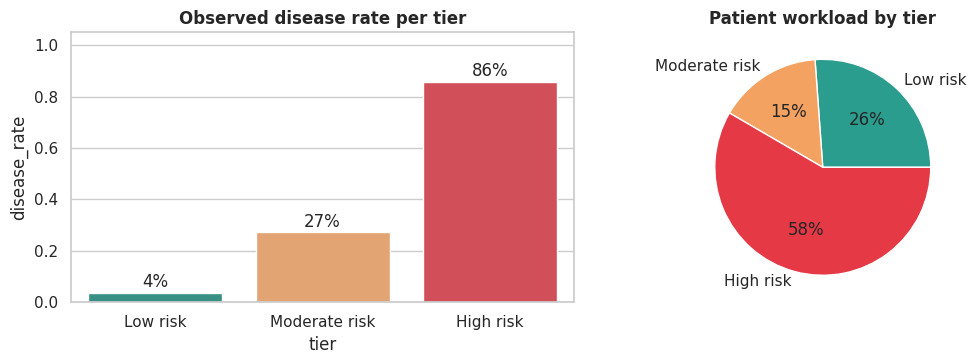

In [27]:
oof_all = cross_val_predict(clone(final_pipe), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
tiers = pd.cut(oof_all, [0, 0.20, THR if THR>0.25 else 0.5, 1.0], labels=["Low risk","Moderate risk","High risk"], include_lowest=True)
tier_tbl = pd.DataFrame({"tier": tiers, "y": y.values}).groupby("tier", observed=True).agg(patients=("y","size"), disease_rate=("y","mean"), cases=("y","sum"))
tier_tbl["% of all patients"] = tier_tbl.patients/len(y); tier_tbl["% of all disease cases captured"] = tier_tbl.cases/y.sum()
display(tier_tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=tier_tbl.index.astype(str), y=tier_tbl.disease_rate, ax=ax[0], palette=["#2a9d8f","#f4a261","#e63946"]); ax[0].set_ylim(0,1.05); ax[0].set_title("Observed disease rate per tier")
for i, v in enumerate(tier_tbl.disease_rate): ax[0].text(i, v+.02, f"{v:.0%}", ha="center")
ax[1].pie(tier_tbl.patients, labels=tier_tbl.index.astype(str), autopct="%1.0f%%", colors=["#2a9d8f","#f4a261","#e63946"]); ax[1].set_title("Patient workload by tier")
savefig("08_risk_tiers")

### 📌 Business insights & actionable recommendations

**What the numbers say**
- **Risk tiers work:** the *Low* tier (26 % of patients) has only a **3.8 %** disease rate; the *High* tier (58 % of patients) has **85.8 %** and contains **90.6 %** of all cases; *Moderate* (15 %) sits at 27.5 %.
- **Cost:** in a *screening* population (10–30 % prevalence) the model cuts expected cost by roughly **46–71 %** at a 10:1 FN:FP cost ratio versus the best naive strategy. In an *already-referred* population like this dataset (55 % prevalence) refer-everybody is hard to beat at standard threshold — there the value is **prioritisation**, and the high-sensitivity mode is cheaper than referring everyone (35.3 vs 44.6 cost units per 100 patients, −21 %).
- **Projected workload (assumption: 20 % prevalence, standard threshold, test sensitivity 0.92 / specificity 0.79):** per 1,000 patients, ≈ 350 are referred instead of 1,000 (**−65 % specialist load**) while ≈ 184 of 200 sick patients (92 %) are caught.

**Recommendations**
| # | Recommendation | Evidence | Owner |
|---|---|---|---|
| 1 | **Adopt 3-tier triage:** Low (p < 0.20) → routine advice & annual re-screen; Moderate (0.20–0.50) → repeat tests / GP review in weeks; High (≥ 0.50) → fast-track cardiology | Tier table: 3.8 % / 27.5 % / 85.8 % disease | Hospital admin, cardiology |
| 2 | **Pick the threshold by setting:** 0.50 where cardiology capacity is tight; **0.35 (recall 96 %)** for community screening camps | §7.3 and cost analysis | Medical director |
| 3 | **Always record ST-segment slope & exercise-angina status** — they carry the most predictive power | ST_Slope Flat/Down 78–83 % vs Up 20 % disease; permutation importance #1 | Cardiology / lab staff |
| 4 | **Make a lipid profile mandatory** — 172 patients (19 %) have no cholesterol value and 88 % of them are sick; the gap hurts both care and model quality | §2.3 | Data-quality / IT |
| 5 | **Target outreach at silent high-risk groups:** men > 55, diabetics (fasting sugar > 120), and *asymptomatic* patients | ASY 79 % vs ATA 14 %; men 63 % vs women 26 %; FastingBS 79 % vs 48 % | Public-health team |
| 6 | **Keep the clinician in the loop:** show the probability, not just a label; never discharge a symptomatic "low-risk" patient on the model alone | 8 false negatives had normal-looking stress tests | Doctors |
| 7 | **Pilot before deployment:** validate on local data, add more female patients, monitor subgroup recall and drift | Female subgroup n = 38; 1980s–90s source data | Data-science team |

## 9. Deployment, Limitations & Contributions

### 9.1 Persist the production model

In [28]:
# Production model = same hyper-parameters, refit on ALL 918 labelled patients (reported metrics above come from the train-only model).
production = clone(tuned[final_name]).fit(X, y)
artifact = {"pipeline": production, "threshold": THR, "threshold_high_sensitivity": THR_HI, "model_name": final_name, "features": RAW_FEATURES,
            "tiers": {"low_max": 0.20, "high_min": THR if THR>0.25 else 0.5}}
joblib.dump(artifact, "model/heart_model.joblib")

results = {"final_model": final_name, "best_params": {k: {a: (b if not isinstance(b, (np.floating, np.integer)) else b.item()) for a, b in v.items()} for k, v in best_params.items()},
           "threshold": THR, "threshold_high_sensitivity": THR_HI, "test_metrics_at_0.5": {k: round(v,4) for k,v in m05.items()}, "test_metrics_at_threshold": {k: round(v,4) for k,v in mT.items()}, "test_metrics_high_sensitivity": {k: round(v,4) for k,v in mH.items()},
           "bootstrap_ci": ci.round(4).to_dict(orient="index"), "saving_grid": saving.astype(float).round(3).to_dict(), "subgroups": sub.round(3).reset_index().astype(str).to_dict(orient="records"),
           "cv_table": tuned_show.to_dict(orient="index"), "baseline_cv": show.to_dict(orient="index"),
           "n_train": len(X_train), "n_test": len(X_test), "cost_table": cost.to_dict(orient="records"), "ablation": ablation.to_dict(orient="records"), "selection_cv": selection_cv.to_dict(orient="records"), "perm_importance": imp.sort_values("mean", ascending=False).head(8).round(4).to_dict(orient="records"), "odds_ratios": odds.round(2).to_dict(),
           "tier_table": tier_tbl.reset_index().astype({"tier": str}).to_dict(orient="records")}
json.dump(results, open("model/results.json", "w"), indent=2, default=float)

# sanity check: reload and predict one patient
art = joblib.load("model/heart_model.joblib")
patient = pd.DataFrame([{"Age":58,"Sex":"M","ChestPainType":"ASY","RestingBP":150,"Cholesterol":0,"FastingBS":1,"RestingECG":"ST","MaxHR":110,"ExerciseAngina":"Y","Oldpeak":2.0,"ST_Slope":"Flat"}])
p = art["pipeline"].predict_proba(patient[art["features"]])[0, 1]
print(f"Example high-risk patient → P(disease) = {p:.1%} → {'REFER' if p >= art['threshold'] else 'routine follow-up'}")

Example high-risk patient → P(disease) = 98.2% → REFER


### 9.2 Run the web demo
```bash
pip install -r requirements.txt
streamlit run app.py
```
The Streamlit app loads `model/heart_model.joblib`, validates inputs, shows the **risk probability, tier and recommended action**, and lists the key risk drivers.

### 9.3 Limitations & future work
- **Small, pooled dataset (918)** from five historical sources (1980s–90s) → possible population shift; needs **external validation** on local Indian hospital data before any real use.
- `Oldpeak`, `ST_Slope`, `ExerciseAngina`, `MaxHR` come from an **exercise stress test** — strong predictors but unavailable at a basic GP visit. A "GP-lite" model without them would be a useful follow-up.
- 172 cholesterol values are missing (coded 0) and are **not missing at random** — median imputation + indicator is a pragmatic, not perfect, fix.
- Test set is small (184) → wide confidence intervals; costs (FN = 10× FP) are **illustrative assumptions**.
- Future work: SHAP explanations, probability calibration, larger multi-centre data, fairness audit across more subgroups, MLOps monitoring for drift.

### 9.4 Individual contribution
This is an **individual project**. All stages — problem definition, data understanding, preprocessing, EDA, feature engineering, modelling, evaluation, business recommendations, the Streamlit app, report and presentation — were carried out by the author (Rohit Dnyaneshwar Mahale, PRN 2125UDSM2043).

### 9.5 References
1. Kaggle — *Heart Failure Prediction Dataset*, fedesoriano (2021). 2. WHO — *Cardiovascular diseases (CVDs)* fact sheet. 3. Pedregosa et al., *Scikit-learn: Machine Learning in Python*, JMLR 12 (2011). 4. Detrano et al., *International application of a new probability algorithm for the diagnosis of coronary artery disease*, Am J Cardiol 64 (1989).